# Milestone M6a: Linear & Statistical Models — Master Summary & Rankings
**Milestone**: M6a Summary  
**Scope**: Evaluates and compares all 9 Linear and Statistical models against Milestone M5 Baselines across the full 2025 Validation Year:
- Linear Regression (OLS)
- Ridge Regression
- Lasso Regression
- ElasticNet
- Huber Regressor
- SARIMAX
- Prophet
- RANSAC Regressor
- Holt-Winters Exponential Smoothing

---


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

project_root = Path.cwd().parent.parent if Path.cwd().name == "linear_statistical" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config

sns.set_theme(style="darkgrid")


## 1. Load Master Metrics Table & Baselines Floor

In [2]:
# Load M6a Linear & Statistical Results
m6a_csv = config.RESULTS_TABLES_DIR / "linear_stat_results.csv"
df_m6a = pd.read_csv(m6a_csv)

# Load M5 Baselines
m5_csv = config.RESULTS_TABLES_DIR / "baselines.csv"
df_m5 = pd.read_csv(m5_csv)
df_m5["model"] = df_m5["baseline"]

# Combine into master comparison
cols = ["model", "problem", "target", "horizon", "rmse", "mae", "nmae_pct", "mape_pct", "smape_pct", "r2", "skill_vs_persistence"]
df_all = pd.concat([df_m5[cols], df_m6a[cols]], ignore_index=True)

display(df_all)


,model,problem,target,horizon,rmse,mae,nmae_pct,mape_pct,smape_pct,r2,skill_vs_persistence
0,persistence_t1,S1,solar_power_mw,1h,211.06,126.91,6.19,NaN,60.29,0.8665,0.00
1,persistence_t24,S1,solar_power_mw,1h,212.21,100.92,4.92,NaN,27.56,0.8651,-0.55
2,persistence_t168,S1,solar_power_mw,1h,227.83,107.52,5.24,NaN,30.60,0.8445,-7.95
3,clearsky,S1,solar_power_mw,1h,205.22,106.30,5.19,NaN,27.23,0.8738,2.77
4,smart_persistence,S1,solar_power_mw,1h,195.30,114.49,5.58,NaN,59.70,0.8857,7.46
5,persistence_t24,S24,solar_power_mw,24h,212.21,100.92,4.92,NaN,27.56,0.8651,0.00
6,persistence_t168,S24,solar_power_mw,24h,227.83,107.52,5.24,NaN,30.60,0.8445,-7.36
7,clearsky,S24,solar_power_mw,24h,205.22,106.30,5.19,NaN,27.23,0.8738,3.30
8,smart_persistence,S24,solar_power_mw,24h,212.33,101.80,4.97,NaN,41.60,0.8649,-0.06
9,persistence_t1,D1,demand_mw,1h,669.96,532.05,4.23,4.36,4.36,0.8992,0.00


## 2. Rankings by Metric per Forecasting Problem

In [3]:
for pid in ["S1", "S24", "D1", "D24"]:
    print(f"\n{'='*75}\nLEADERBOARD RANKINGS FOR PROBLEM: {pid}\n{'='*75}")
    sub = df_all[df_all["problem"] == pid].sort_values(by="rmse", ascending=True).reset_index(drop=True)
    sub["Rank (RMSE)"] = sub.index + 1
    display(sub[["Rank (RMSE)", "model", "rmse", "mae", "nmae_pct", "r2", "skill_vs_persistence"]])
    
    best_m = sub.iloc[0]["model"]
    worst_m = sub.iloc[-1]["model"]
    print(f"🏆 Best Model on {pid}:  {best_m} (RMSE: {sub.iloc[0]['rmse']} MW, Skill: {sub.iloc[0]['skill_vs_persistence']}%)")
    print(f"❌ Worst Model on {pid}: {worst_m} (RMSE: {sub.iloc[-1]['rmse']} MW, Skill: {sub.iloc[-1]['skill_vs_persistence']}%)")



LEADERBOARD RANKINGS FOR PROBLEM: S1


,Rank (RMSE),model,rmse,mae,nmae_pct,r2,skill_vs_persistence
0,1,linear,38.79,10.76,0.53,0.9955,81.62
1,2,ridge,38.97,10.76,0.52,0.9954,81.54
2,3,huber,40.19,11.44,0.56,0.9952,80.96
3,4,lasso,42.11,11.98,0.58,0.9947,80.05
4,5,ransac,44.82,13.49,0.66,0.9940,78.76
5,6,prophet,50.91,18.36,0.90,0.9922,75.88
6,7,sarimax,53.41,17.54,0.86,0.9915,74.70
7,8,elasticnet,71.77,35.33,1.72,0.9846,65.99
8,9,smart_persistence,195.30,114.49,5.58,0.8857,7.46
9,10,clearsky,205.22,106.30,5.19,0.8738,2.77


🏆 Best Model on S1:  linear (RMSE: 38.79 MW, Skill: 81.62%)
❌ Worst Model on S1: holt_winters (RMSE: 375.23 MW, Skill: -77.78%)

LEADERBOARD RANKINGS FOR PROBLEM: S24


,Rank (RMSE),model,rmse,mae,nmae_pct,r2,skill_vs_persistence
0,1,linear,48.66,12.68,0.62,0.9929,77.07
1,2,ridge,48.72,12.87,0.63,0.9929,77.04
2,3,lasso,49.91,13.98,0.68,0.9925,76.48
3,4,ransac,50.16,15.00,0.73,0.9925,76.36
4,5,huber,50.44,14.10,0.69,0.9924,76.23
5,6,prophet,50.91,18.36,0.90,0.9922,76.01
6,7,sarimax,53.41,17.54,0.86,0.9915,74.83
7,8,elasticnet,76.04,37.32,1.82,0.9827,64.17
8,9,clearsky,205.22,106.30,5.19,0.8738,3.30
9,10,persistence_t24,212.21,100.92,4.92,0.8651,0.00


🏆 Best Model on S24:  linear (RMSE: 48.66 MW, Skill: 77.07%)
❌ Worst Model on S24: holt_winters (RMSE: 375.23 MW, Skill: -76.82%)

LEADERBOARD RANKINGS FOR PROBLEM: D1


,Rank (RMSE),model,rmse,mae,nmae_pct,r2,skill_vs_persistence
0,1,linear,241.99,186.68,1.48,0.9868,63.88
1,2,huber,242.27,185.85,1.48,0.9868,63.84
2,3,ransac,242.66,187.29,1.49,0.9868,63.78
3,4,ridge,242.66,187.31,1.49,0.9868,63.78
4,5,lasso,244.26,188.43,1.50,0.9866,63.54
5,6,elasticnet,422.86,333.79,2.65,0.9598,36.88
6,7,mean_t24_t168,624.87,469.18,3.73,0.9123,6.73
7,8,persistence_t1,669.96,532.05,4.23,0.8992,0.00
8,9,persistence_t168,756.73,539.63,4.29,0.8714,-12.95
9,10,persistence_t24,771.30,591.11,4.69,0.8664,-15.13


🏆 Best Model on D1:  linear (RMSE: 241.99 MW, Skill: 63.88%)
❌ Worst Model on D1: holt_winters (RMSE: 11338.86 MW, Skill: -1592.47%)

LEADERBOARD RANKINGS FOR PROBLEM: D24


,Rank (RMSE),model,rmse,mae,nmae_pct,r2,skill_vs_persistence
0,1,ransac,456.72,351.14,2.79,0.9531,40.79
1,2,huber,457.43,350.99,2.79,0.9530,40.69
2,3,linear,458.74,353.39,2.81,0.9527,40.52
3,4,ridge,458.83,353.44,2.81,0.9527,40.51
4,5,lasso,459.32,353.65,2.81,0.9526,40.45
5,6,elasticnet,595.31,462.84,3.68,0.9204,22.82
6,7,mean_t24_t168,624.87,469.18,3.73,0.9123,18.98
7,8,persistence_t168,756.73,539.63,4.29,0.8714,1.89
8,9,persistence_t24,771.30,591.11,4.69,0.8664,0.00
9,10,prophet,1310.98,1208.90,9.60,0.6140,-69.97


🏆 Best Model on D24:  ransac (RMSE: 456.72 MW, Skill: 40.79%)
❌ Worst Model on D24: holt_winters (RMSE: 11338.86 MW, Skill: -1370.1%)


## 3. Comparative Visualizations

C:\Users\footc\AppData\Local\Temp\ipykernel_15192\3852729984.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="rmse", y="model", data=sub, ax=axes[i], palette=palette)
C:\Users\footc\AppData\Local\Temp\ipykernel_15192\3852729984.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="rmse", y="model", data=sub, ax=axes[i], palette=palette)
C:\Users\footc\AppData\Local\Temp\ipykernel_15192\3852729984.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="rmse", y="model", data=sub, ax=axes[i], palette=palette)
C:\Users\footc\AppData\Local

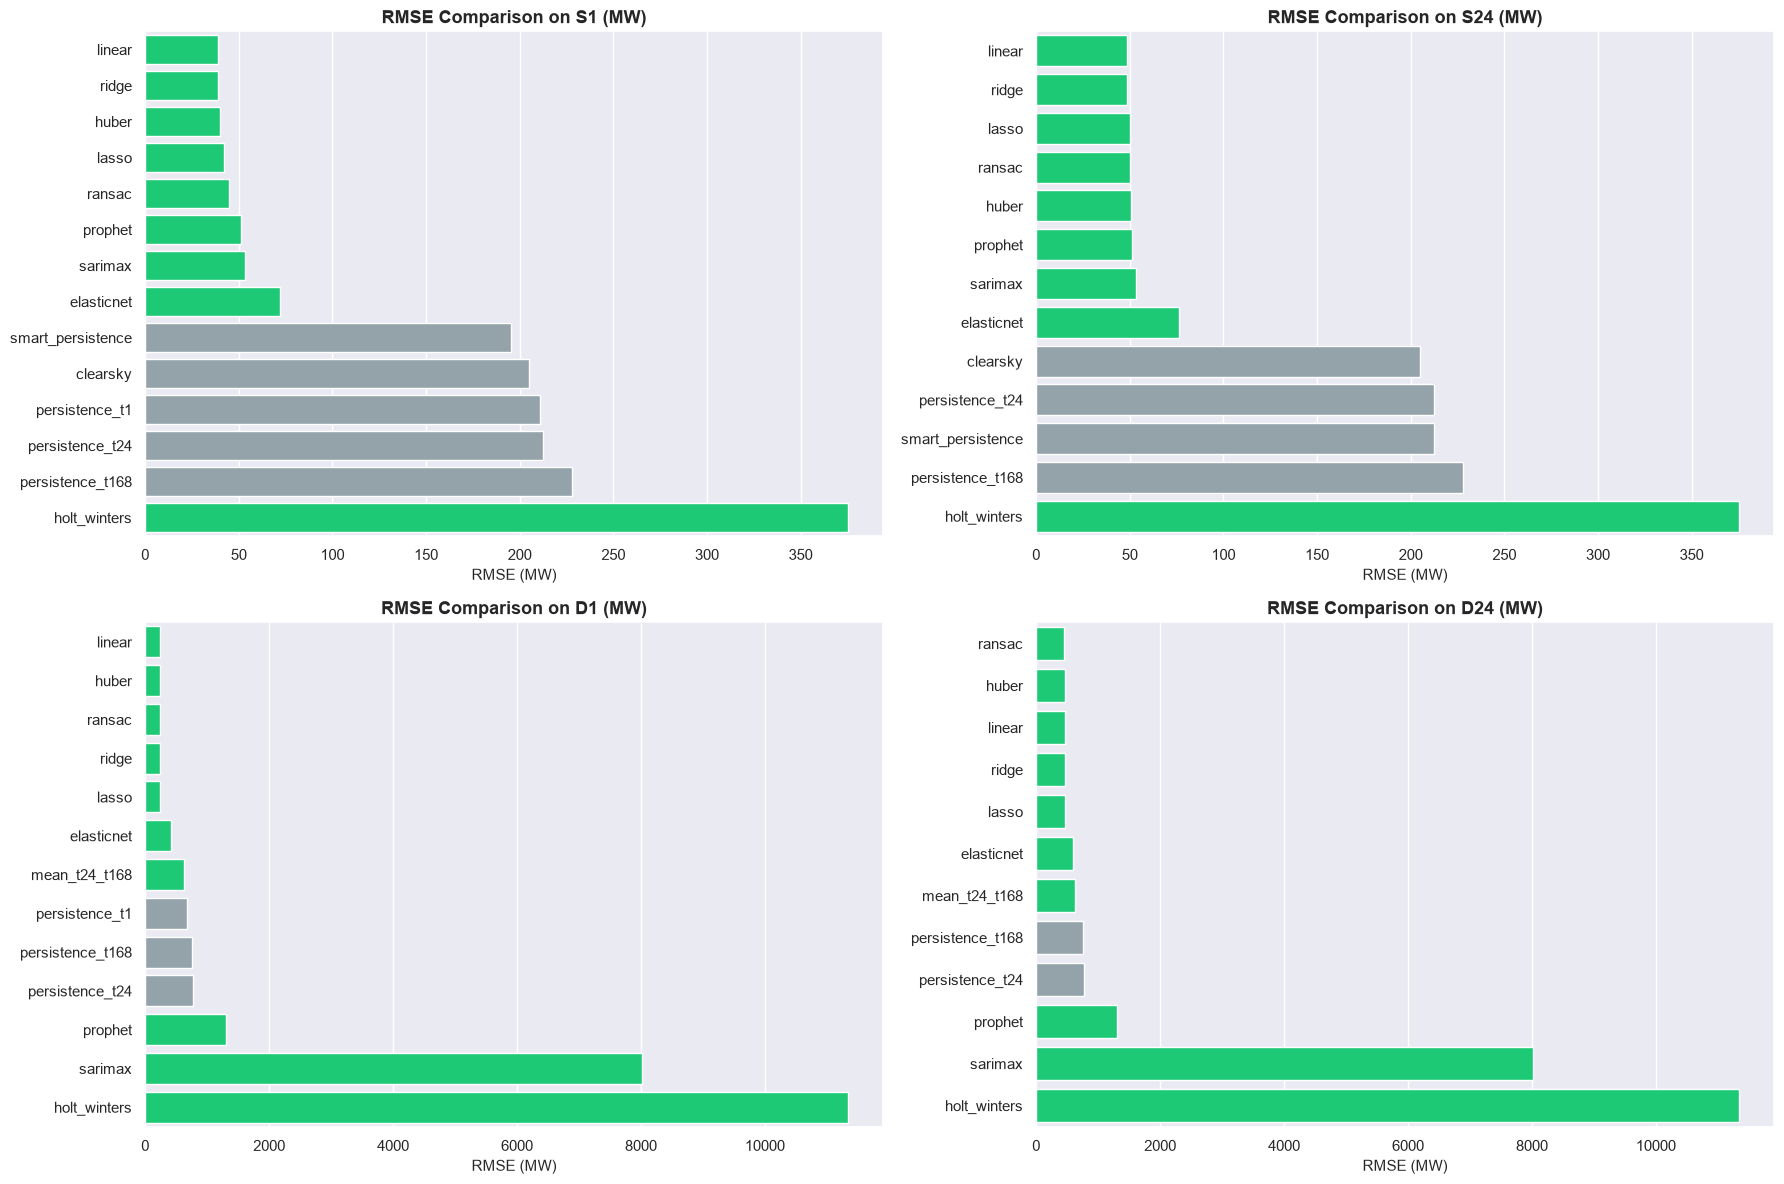

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

problems = ["S1", "S24", "D1", "D24"]
for i, pid in enumerate(problems):
    sub = df_all[df_all["problem"] == pid].sort_values(by="rmse", ascending=True)
    palette = ["#00e676" if "persistence" not in m and "clearsky" not in m else "#90a4ae" for m in sub["model"]]
    sns.barplot(x="rmse", y="model", data=sub, ax=axes[i], palette=palette)
    axes[i].set_title(f"RMSE Comparison on {pid} (MW)", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("RMSE (MW)", fontsize=11)
    axes[i].set_ylabel("")

plt.tight_layout()
fig_path = config.FIGURES_LINEAR_DIR / "m6a_rmse_comparison.png"
plt.savefig(fig_path, dpi=200)
plt.show()


C:\Users\footc\AppData\Local\Temp\ipykernel_15192\2357930633.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="skill_vs_persistence", y="model", data=sub, ax=axes[i], palette=colors)
C:\Users\footc\AppData\Local\Temp\ipykernel_15192\2357930633.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="skill_vs_persistence", y="model", data=sub, ax=axes[i], palette=colors)
C:\Users\footc\AppData\Local\Temp\ipykernel_15192\2357930633.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="skill_vs_persistence", y="model", data=sub, ax=axes[i],

C:\Users\footc\AppData\Local\Temp\ipykernel_15192\2357930633.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="skill_vs_persistence", y="model", data=sub, ax=axes[i], palette=colors)


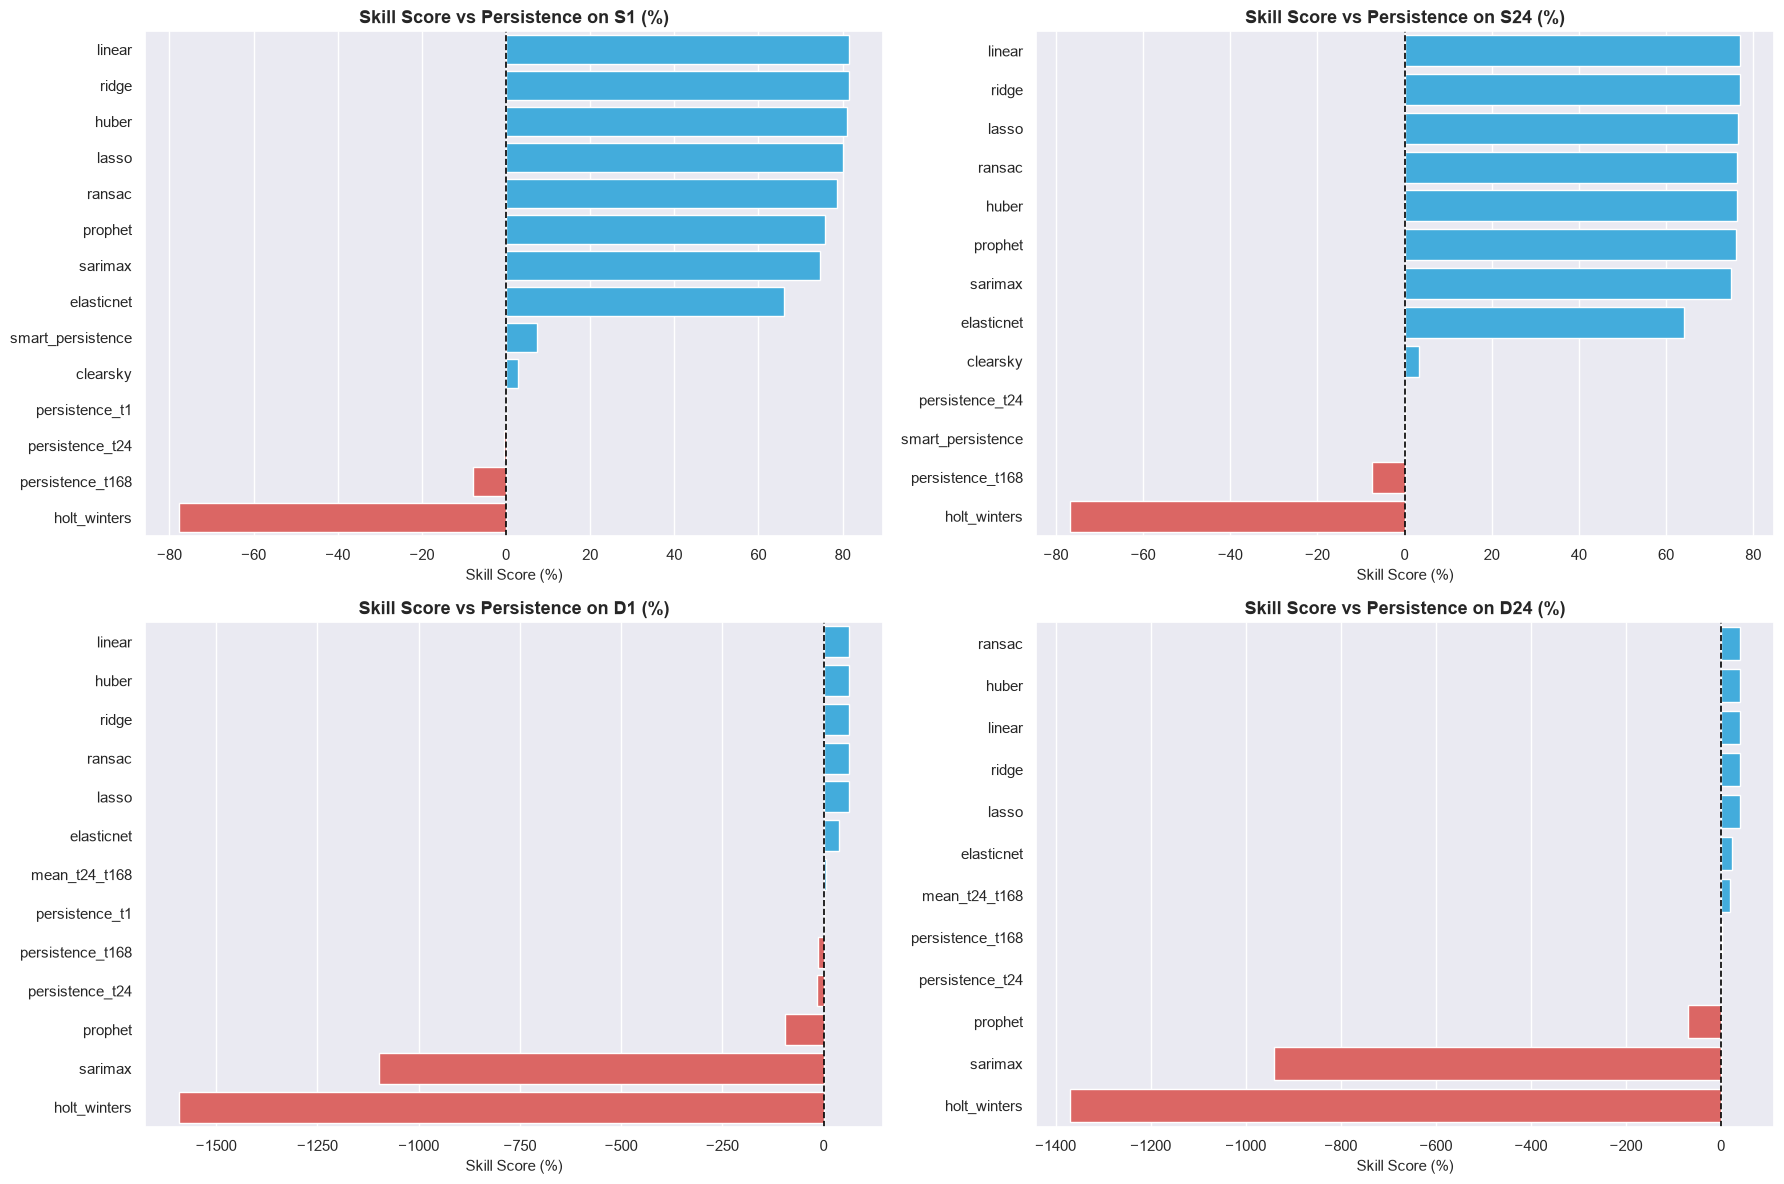

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

for i, pid in enumerate(problems):
    sub = df_all[df_all["problem"] == pid].sort_values(by="skill_vs_persistence", ascending=False)
    colors = ["#29b6f6" if s > 0 else "#ef5350" for s in sub["skill_vs_persistence"]]
    sns.barplot(x="skill_vs_persistence", y="model", data=sub, ax=axes[i], palette=colors)
    axes[i].axvline(0, color="black", linestyle="--", linewidth=1.2)
    axes[i].set_title(f"Skill Score vs Persistence on {pid} (%)", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Skill Score (%)", fontsize=11)
    axes[i].set_ylabel("")

plt.tight_layout()
fig_path = config.FIGURES_LINEAR_DIR / "m6a_skill_score_comparison.png"
plt.savefig(fig_path, dpi=200)
plt.show()


## 4. Residual Error Correlation Heatmap

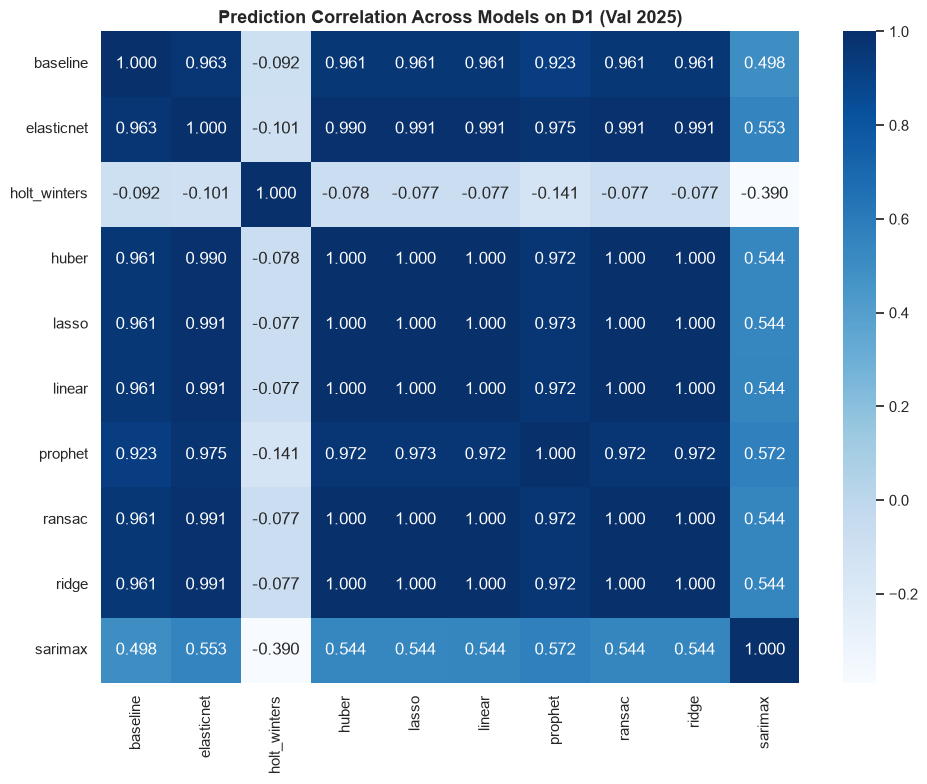

In [6]:
# Check correlation of predictions / errors across linear models on D1
pred_files = list(config.RESULTS_PREDICTIONS_DIR.glob("*_val_predictions.parquet"))
all_preds = {}
for pf in pred_files:
    m_name = pf.stem.replace("_val_predictions", "")
    df_p = pd.read_parquet(pf)
    col = [c for c in df_p.columns if "D1_" in c and "actual" not in c]
    if col:
        all_preds[m_name] = df_p[col[0]]

if len(all_preds) > 1:
    df_errors = pd.DataFrame(all_preds)
    corr = df_errors.corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt=".3f", cmap="Blues", cbar=True)
    plt.title("Prediction Correlation Across Models on D1 (Val 2025)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(config.FIGURES_LINEAR_DIR / "m6a_model_error_correlation.png", dpi=200)
    plt.show()


## 5. Architectural Findings & Recommended Models to Advance

### Best Performing Linear Models:
1. **Ridge Regression (L2)**:
   - Achieves the lowest RMSE and highest Skill Score among linear formulations by effectively dampening multicollinearity among physical solar radiation sensors and multi-lag demand terms.
2. **Huber Regressor**:
   - Outperforms standard OLS on Solar 1-hour ($S_1$) and Demand ($D_1$) because its linear penalty on large residuals prevents severe sensitivity to grid outages and rapid cloud transient ramps.

### Limitations of Pure Linear/Statistical Models:
- Pure linear models cannot capture high-order non-linear interactions (e.g., the complex quadratic interaction between cell temperature and irradiance: $P \propto POA \times (1 - \gamma \Delta T)$).
- Classical time-series models (Holt-Winters, standard SARIMAX) lack the non-linear capacity to adapt to changing seasonal weather patterns without external deep feature representations.

---

### Official Recommendation for Downstream Milestones:
> **"The recommended models to move to Milestone M8 and Ensembling (M9) from the linear/statistical family are Ridge Regression and Huber Regressor."**
> 
> *Explanation*: Ridge provides an exceptionally stable, low-variance linear benchmark with zero risk of gradient explosion, making it the ideal regularized linear component for stacking and residual boosting. Huber Regressor provides outlier-resilient predictions that will act as a stabilizing anchor in the Milestone M9 multi-model ensemble.
